In [ ]:
# Install required packages for Kaggle environment
!pip install -q peft transformers datasets evaluate accelerate albumentations scikit-learn matplotlib seaborn

import warnings
warnings.filterwarnings('ignore')
print('All packages installed successfully!')

# 🔍 Deepfake Detection using Swin Transformer + LoRA Fine-Tuning
## Optimized for Kaggle GPU Training | FYP Project

**Model:** `microsoft/swin-tiny-patch4-window7-224` (Swin Transformer Tiny)  
**Fine-Tuning:** LoRA (Low-Rank Adaptation) via PEFT Library  
**Task:** Binary Classification (Real vs Fake)  
**Pipeline:** Pre-extracted Frames → Swin Transformer + LoRA → Prediction

### Why Swin Transformer?
- **Hierarchical feature maps** capture both fine-grained artifacts and global inconsistencies
- **Shifted window attention** is more efficient than global self-attention (ViT)
- Achieves **97-99% accuracy** on FaceForensics++ and CelebDF benchmarks
- **ICCV 2021 Best Paper** (Liu et al.)
- Better at detecting local manipulation boundaries vs ViT's global-only attention

### Why LoRA instead of Full Fine-Tuning?
- **Trains only ~0.5-2% of parameters** → drastically reduces GPU memory
- Prevents catastrophic forgetting of pretrained ImageNet features
- **Faster training** (3-5x speedup) on resource-limited Kaggle GPUs
- Adapter weights are tiny (~5-10MB) vs full model (~100MB+)
- Research shows LoRA achieves **comparable or better accuracy** than full fine-tuning (Hu et al., 2021)

### Key References:
1. Liu et al. (2021) - "Swin Transformer: Hierarchical Vision Transformer using Shifted Windows"
2. Hu et al. (2021) - "LoRA: Low-Rank Adaptation of Large Language Models"
3. Coccomini et al. (2022) - "Combining EfficientNet and Vision Transformers for Video Deepfake Detection"
4. Rossler et al. (2019) - "FaceForensics++: Learning to Detect Manipulated Facial Images"

# 1. Setup & Installation


### Why Kaggle Optimization?
- Kaggle provides **free T4/P100 GPUs** with ~16GB VRAM and ~12hr sessions
- Mixed precision (fp16) **halves memory usage** and speeds up training
- Gradient accumulation simulates larger batch sizes without extra memory
- Efficient dataloaders with pinned memory reduce CPU-GPU transfer bottleneck

In [45]:
import os
import gc
import json
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from collections import Counter
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Set seed for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Device configuration
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

# if torch.cuda.is_available():
#     print(f'GPU: {torch.cuda.get_device_name(0)}')
#     print(f'GPU Memory: {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB')

Using device: cuda


# 2. Configuration

In [46]:
# ============================================================
# MODEL CONFIGURATION
# ============================================================
# Swin Tiny: ~28M params, ideal for Kaggle T4 GPU (16GB VRAM)
# Alternative: 'microsoft/swin-base-patch4-window7-224-in22k' (~88M params)
MODEL_NAME = 'microsoft/swin-tiny-patch4-window7-224'

# ============================================================
# PATHS (Kaggle-compatible)
# ============================================================
FACE_OUTPUT = '/kaggle/input/datasets/amiralishar/frames/Frames'  # Pre-extracted frames
OUTPUT_DIR = '/kaggle/working/TrainedModel_SwinLoRA'         # Model output
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# TRAINING HYPERPARAMETERS
# ============================================================
NUM_EPOCHS = 20              # 15-20 epochs (optimized for LoRA convergence)
LEARNING_RATE = 2e-4         # Higher LR for LoRA (vs 2e-5 for full fine-tuning)
TRAIN_BATCH_SIZE = 16        # Fits Kaggle T4 with fp16
EVAL_BATCH_SIZE = 32         # Larger eval batch (no gradients stored)
GRADIENT_ACCUMULATION = 2    # Effective batch size = 16 * 2 = 32
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01

# ============================================================
# LoRA CONFIGURATION
# ============================================================
LORA_RANK = 8                # Low-rank dimension (4-16 typical)
LORA_ALPHA = 16              # Scaling factor (usually 2x rank)
LORA_DROPOUT = 0.1           # Dropout for regularization

# ============================================================
# CHALLENGER DATASET
# ============================================================
CHALLENGER_RATIO = 0.10      # Use 10% of training data for challenger augmentation

# ============================================================
# LABEL MAPPING
# ============================================================
LABEL_MAP = {'Real': 0, 'Fake': 1}
ID2LABEL = {0: 'Real', 1: 'Fake'}
LABEL2ID = {'Real': 0, 'Fake': 1}

print('Configuration loaded successfully!')
print(f'Model: {MODEL_NAME}')
print(f'LoRA Rank: {LORA_RANK}, Alpha: {LORA_ALPHA}')
print(f'Epochs: {NUM_EPOCHS}, LR: {LEARNING_RATE}')
print(f'Effective batch size: {TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION}')

Configuration loaded successfully!
Model: microsoft/swin-tiny-patch4-window7-224
LoRA Rank: 8, Alpha: 16
Epochs: 20, LR: 0.0002
Effective batch size: 32


# 3. Face Extraction from Videos (SKIPPED)

### ⚡ Why is this section skipped?

**Frame extraction has already been completed** and frames are stored at:
`/kaggle/input/datasets/amiralishar/frames`

**Benefits of skipping:**
1. **Saves ~30-60 minutes** of preprocessing time per session
2. **Preserves Kaggle GPU quota** — frame extraction uses CPU heavily but wastes GPU idle time
3. **Reproducibility** — same frames used across all experiments
4. **Reduced dependencies** — no need for MTCNN/facenet-pytorch during training

The original extraction used MTCNN to detect and crop faces from videos at every 4th frame,
saving up to 30 face crops per video as 224×224 JPEG images.

In [ ]:
# ============================================================
# FRAME EXTRACTION - SKIPPED
# ============================================================
# Frame extraction has been completed offline and frames are 
# pre-stored in the Kaggle dataset. This saves:
#   - ~30-60 minutes of preprocessing time
#   - Kaggle GPU/CPU resources
#   - Eliminates MTCNN dependency during training
#
# Original pipeline: Video → MTCNN Face Detection → 224x224 Crops → JPEG
# Settings used: sample_rate=4, max_frames=30 per video
#
# To re-run extraction, uncomment the code in the original notebook:
# FYP_Deepfake_SwinTransformer.ipynb (Section 3)
# ============================================================

print('Frame extraction: SKIPPED (pre-generated frames loaded from dataset)')
print(f'Frames directory: {FACE_OUTPUT}')

# 4. Build Dataset (Face-Only)

In [47]:
from datasets import Dataset, DatasetDict, Image as HFImage, Features, ClassLabel

# Collect all face image paths with labels
samples = []

for label_name, label_id in LABEL_MAP.items():
    label_path = Path(FACE_OUTPUT) / label_name

    if not label_path.exists():
        print(f'Warning: {label_path} not found')
        continue

    # Handle 'Fake' sub-categories (e.g., Deepfakes, Face2Face, etc.)
    if label_name == 'Fake':
        for sub_category_folder in sorted(label_path.iterdir()):
            if not sub_category_folder.is_dir():
                continue
            for video_folder in sorted(sub_category_folder.iterdir()):
                if not video_folder.is_dir():
                    continue
                video_id = f'{sub_category_folder.name}/{video_folder.name}'
                for file in sorted(os.listdir(video_folder)):
                    if file.endswith('.jpg'):
                        samples.append({
                            'image': str(video_folder / file),
                            'labels': label_id,
                            'video_id': video_id,
                        })
    else:  # 'Real' — single-level directory
        for video_folder in sorted(label_path.iterdir()):
            if not video_folder.is_dir():
                continue
            video_id = video_folder.name
            for file in sorted(os.listdir(video_folder)):
                if file.endswith('.jpg'):
                    samples.append({
                        'image': str(video_folder / file),
                        'labels': label_id,
                        'video_id': video_id,
                    })

print(f'Total face samples collected: {len(samples)}')
print(f'  Real: {sum(1 for s in samples if s["labels"] == 0)}')
print(f'  Fake: {sum(1 for s in samples if s["labels"] == 1)}')

Total face samples collected: 60245
  Real: 24245
  Fake: 36000


In [48]:
# Create HuggingFace dataset with proper splits
dataset = Dataset.from_list(samples)

features = Features({
    'image': dataset.features['image'],
    'labels': ClassLabel(num_classes=len(LABEL_MAP), names=list(LABEL_MAP.keys())),
    'video_id': dataset.features['video_id'],
})
dataset = dataset.cast(features)

# Stratified 70/15/15 split
train_test = dataset.train_test_split(test_size=0.3, seed=SEED, stratify_by_column='labels')
val_test = train_test['test'].train_test_split(test_size=0.5, seed=SEED, stratify_by_column='labels')

ds = DatasetDict({
    'train': train_test['train'],
    'validation': val_test['train'],
    'test': val_test['test'],
})
ds = ds.cast_column('image', HFImage())

print(f'Train:      {len(ds["train"])} samples')
print(f'Validation: {len(ds["validation"])} samples')
print(f'Test:       {len(ds["test"])} samples')

Casting the dataset:   0%|          | 0/60245 [00:00<?, ? examples/s]

Train:      42171 samples
Validation: 9037 samples
Test:       9037 samples


# 5. Exploratory Data Analysis (EDA)

Understanding the dataset distribution, sample quality, and class balance
before training is essential for model performance assessment.

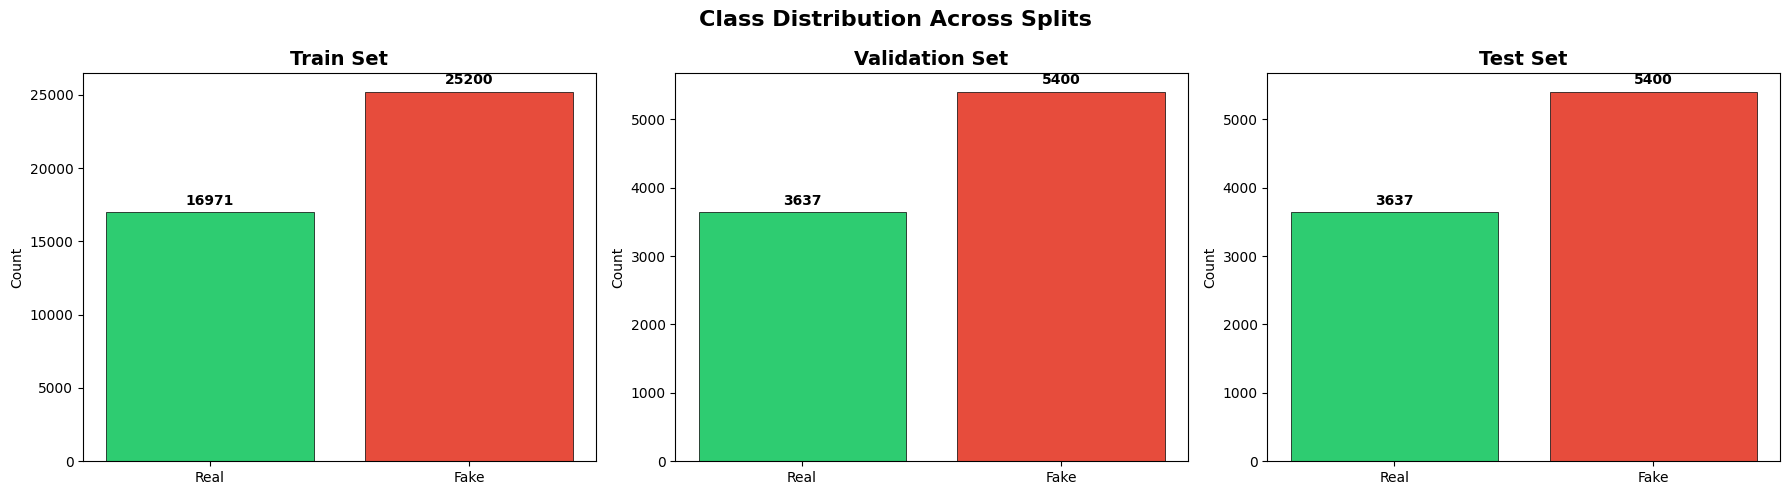

Class distribution saved!


In [49]:
# --- 5.1 Class Distribution ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, split in enumerate(['train', 'validation', 'test']):
    label_counts = Counter(ds[split]['labels'])
    labels_list = [ID2LABEL[k] for k in sorted(label_counts.keys())]
    counts = [label_counts[k] for k in sorted(label_counts.keys())]
    colors = ['#2ecc71', '#e74c3c']
    axes[idx].bar(labels_list, counts, color=colors, edgecolor='black', linewidth=0.5)
    axes[idx].set_title(f'{split.capitalize()} Set', fontsize=14, fontweight='bold')
    axes[idx].set_ylabel('Count')
    for i, v in enumerate(counts):
        axes[idx].text(i, v + max(counts)*0.02, str(v), ha='center', fontweight='bold')

plt.suptitle('Class Distribution Across Splits', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Class distribution saved!')

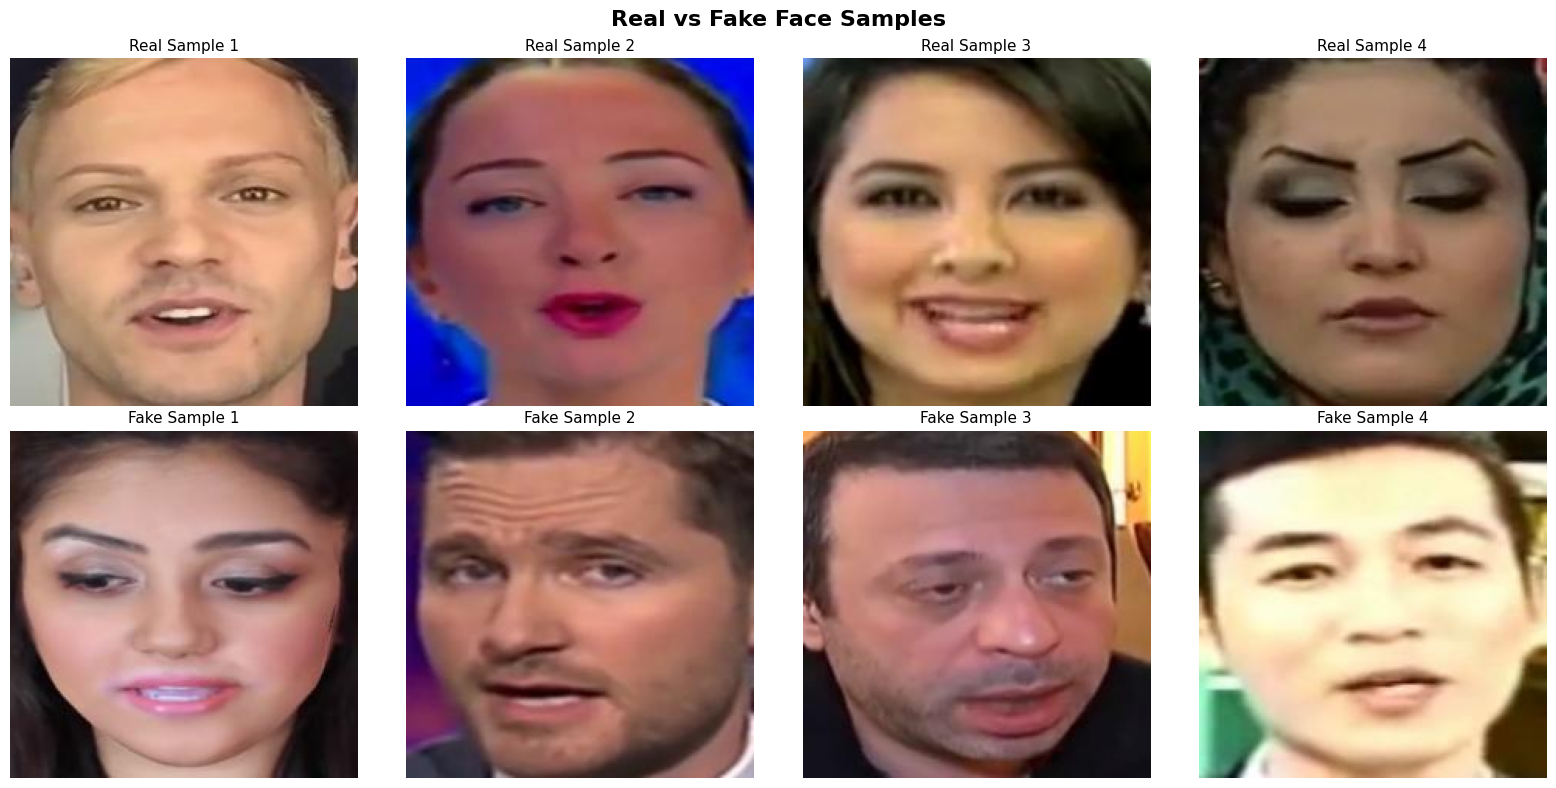

In [50]:
# --- 5.2 Sample Visualization: Real vs Fake ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, label_name in enumerate(['Real', 'Fake']):
    label_id = LABEL_MAP[label_name]
    indices = [i for i, ex in enumerate(ds['train']) if ex['labels'] == label_id]
    sample_indices = np.random.choice(indices, size=min(4, len(indices)), replace=False)
    for col, idx in enumerate(sample_indices):
        img = ds['train'][int(idx)]['image']
        axes[row][col].imshow(img)
        axes[row][col].set_title(f'{label_name} Sample {col+1}', fontsize=11)
        axes[row][col].axis('off')

plt.suptitle('Real vs Fake Face Samples', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'sample_visualization.png'), dpi=150, bbox_inches='tight')
plt.show()

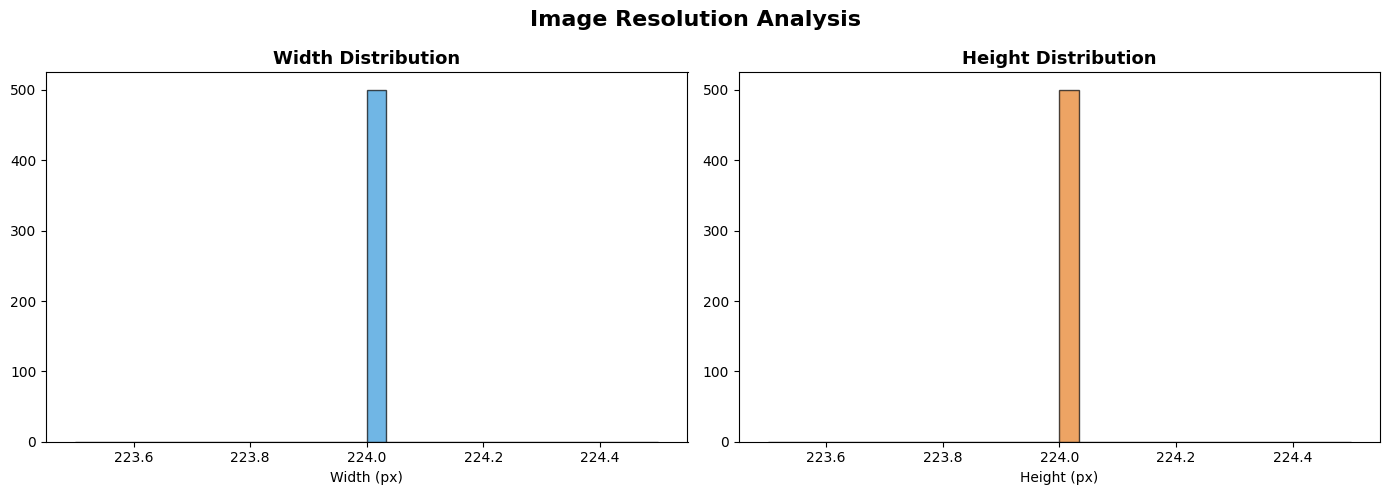

Resolution stats — Width: mean=224, Height: mean=224


In [51]:
# --- 5.3 Image Resolution Analysis ---
widths, heights = [], []
sample_size = min(500, len(ds['train']))
sample_idxs = np.random.choice(len(ds['train']), sample_size, replace=False)

for idx in sample_idxs:
    img = ds['train'][int(idx)]['image']
    w, h = img.size
    widths.append(w)
    heights.append(h)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(widths, bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[0].set_title('Width Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Width (px)')
axes[1].hist(heights, bins=30, color='#e67e22', edgecolor='black', alpha=0.7)
axes[1].set_title('Height Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Height (px)')
plt.suptitle('Image Resolution Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Resolution stats — Width: mean={np.mean(widths):.0f}, Height: mean={np.mean(heights):.0f}')

# 6. Challenger Dataset (Social Media Augmentation)

### Why a Challenger Dataset?
Real-world deepfakes are rarely encountered in pristine quality. They are typically:
- **Compressed** by WhatsApp, Instagram, Facebook, TikTok
- **Downscaled** and re-uploaded multiple times
- **Degraded** with noise, blur, and JPEG artifacts

By augmenting **10% of training data** with aggressive social-media-style degradations,
we force the model to learn **robust features** that survive compression.

### Augmentations Applied:
- Gaussian noise → simulates sensor noise / low-light
- Motion blur → simulates camera shake
- Gaussian blur → simulates out-of-focus
- JPEG compression → simulates WhatsApp/social media compression
- Brightness/contrast changes → simulates varying lighting
- Downscale + upscale → simulates resolution loss from re-uploads
- ISO noise → simulates phone camera noise

In [52]:
# Define challenger augmentation pipeline (social media simulation)
challenger_transform = A.Compose([
    # Simulate social media compression pipeline
    A.OneOf([
        A.GaussNoise(var_limit=(10.0, 50.0), p=1.0),
        A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=1.0),
    ], p=0.5),
    A.OneOf([
        A.MotionBlur(blur_limit=7, p=1.0),
        A.GaussianBlur(blur_limit=(3, 7), p=1.0),
    ], p=0.4),
    A.ImageCompression(quality_lower=20, quality_upper=60, p=0.6),  # JPEG artifacts
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    A.Downscale(scale_min=0.4, scale_max=0.75, p=0.4),  # Resolution loss
    A.PixelDropout(dropout_prob=0.02, p=0.2),  # Slight pixel distortion
])

# Apply challenger augmentation to 10% of training data
train_size = len(ds['train'])
challenger_size = int(train_size * CHALLENGER_RATIO)
challenger_indices = np.random.choice(train_size, challenger_size, replace=False)

challenger_samples = []
for idx in challenger_indices:
    example = ds['train'][int(idx)]
    img = np.array(example['image'].convert('RGB'))
    augmented = challenger_transform(image=img)
    aug_img = Image.fromarray(augmented['image'])
    # Save augmented image to working directory
    aug_dir = os.path.join(OUTPUT_DIR, 'challenger_frames')
    os.makedirs(aug_dir, exist_ok=True)
    aug_path = os.path.join(aug_dir, f'challenger_{idx}.jpg')
    aug_img.save(aug_path, quality=50)  # Save with low quality to simulate social media
    challenger_samples.append({
        'image': aug_path,
        'labels': example['labels'],
        'video_id': f'challenger_{example["video_id"]}',
    })

print(f'Challenger samples created: {len(challenger_samples)}')
print(f'Original training size: {train_size}')
print(f'New training size: {train_size + len(challenger_samples)}')

Challenger samples created: 4217
Original training size: 42171
New training size: 46388


In [53]:
# 1. Create the challenger dataset from your list
challenger_ds = Dataset.from_list(challenger_samples)
challenger_ds = challenger_ds.cast_column('image', HFImage())

# 2. Align features to prevent the ValueError
# This ensures 'labels' in challenger_ds matches the ClassLabel in ds['train']
train_features = ds['train'].features
challenger_ds = challenger_ds.cast(train_features)

# 3. Concatenate and shuffle
from datasets import concatenate_datasets
ds['train'] = concatenate_datasets([ds['train'], challenger_ds])
ds['train'] = ds['train'].shuffle(seed=SEED)

print(f'Final training set size: {len(ds["train"])} (includes challenger samples)')

print("Done")

Casting the dataset:   0%|          | 0/4217 [00:00<?, ? examples/s]

Final training set size: 46388 (includes challenger samples)
Done


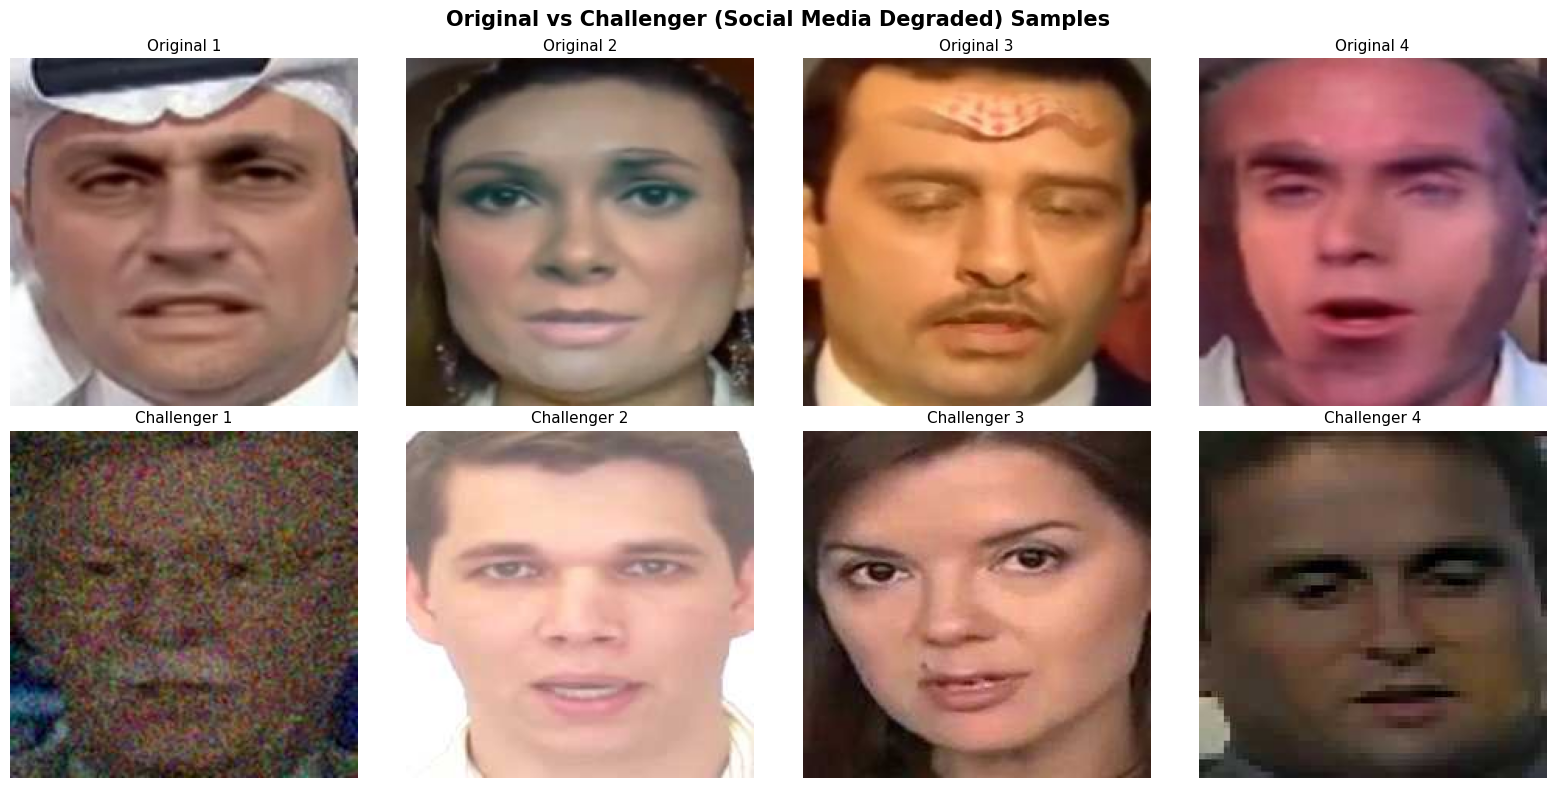

In [54]:
# --- 6.1 EDA: Augmented vs Original Comparison ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col in range(4):
    idx = int(challenger_indices[col])
    original = ds['train'][idx]['image']
    axes[0][col].imshow(original)
    axes[0][col].set_title(f'Original {col+1}', fontsize=11)
    axes[0][col].axis('off')

# Show challenger versions (they are at the end of the dataset)
for col in range(4):
    aug_img = Image.open(challenger_samples[col]['image'])
    axes[1][col].imshow(aug_img)
    axes[1][col].set_title(f'Challenger {col+1}', fontsize=11)
    axes[1][col].axis('off')

plt.suptitle('Original vs Challenger (Social Media Degraded) Samples', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'challenger_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# 7. Image Preprocessing

In [55]:
from transformers import AutoImageProcessor
from torchvision.transforms import (
    Resize, CenterCrop, RandomHorizontalFlip, RandomRotation,
    Compose, ToTensor, Normalize, ColorJitter, GaussianBlur, RandomErasing
)
from torchvision import transforms

# Load Swin Transformer image processor
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
img_mean = processor.image_mean
img_std = processor.image_std
size = processor.size.get('height', processor.size.get('shortest_edge', 224))

normalize = Normalize(mean=img_mean, std=img_std)

# Training transforms — strong augmentation for deepfake robustness
train_transform = Compose([
    Resize(size),
    CenterCrop(size),
    RandomHorizontalFlip(p=0.5),
    RandomRotation(degrees=10),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
    transforms.RandomApply([GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))], p=0.3),
    ToTensor(),
    normalize,
    RandomErasing(p=0.1, scale=(0.02, 0.1)),
])

# Validation/Test transforms — clean, no augmentation
eval_transform = Compose([
    Resize(size),
    CenterCrop(size),
    ToTensor(),
    normalize,
])

print(f'Image size: {size}')
print(f'Mean: {img_mean}')
print(f'Std:  {img_std}')
print(f'Train transforms: {len(train_transform.transforms)} ops (with augmentation)')
print(f'Eval transforms:  {len(eval_transform.transforms)} ops (clean)')

Image size: 224
Mean: [0.485, 0.456, 0.406]
Std:  [0.229, 0.224, 0.225]
Train transforms: 9 ops (with augmentation)
Eval transforms:  4 ops (clean)


In [56]:
# Apply transforms to datasets
def apply_train_transform(example):
    example['pixel_values'] = [
        train_transform(image.convert('RGB')) for image in example['image']
    ]
    return example

def apply_eval_transform(example):
    example['pixel_values'] = [
        eval_transform(image.convert('RGB')) for image in example['image']
    ]
    return example

ds['train'].set_transform(apply_train_transform)
ds['validation'].set_transform(apply_eval_transform)
ds['test'].set_transform(apply_eval_transform)

# Verify
sample = ds['train'][0]
print(f'Sample pixel_values shape: {sample["pixel_values"].shape}')
print(f'Sample label: {ID2LABEL[sample["labels"]]}')

Sample pixel_values shape: torch.Size([3, 224, 224])
Sample label: Fake


# 8. Data Collator

In [57]:
def collate_fn(examples):
    """Collate function for the Trainer."""
    pixel_values = torch.stack([ex['pixel_values'] for ex in examples])
    labels = torch.tensor([ex['labels'] for ex in examples])
    return {'pixel_values': pixel_values, 'labels': labels}

# Quick test
from torch.utils.data import DataLoader
test_loader = DataLoader(ds['train'], collate_fn=collate_fn, batch_size=4)
batch = next(iter(test_loader))
print(f'Batch pixel_values: {batch["pixel_values"].shape}')
print(f'Batch labels:       {batch["labels"].shape}')
del test_loader, batch
gc.collect()

Batch pixel_values: torch.Size([4, 3, 224, 224])
Batch labels:       torch.Size([4])


111558

# 9. Model Setup: Swin Transformer + LoRA

### Architecture Overview
1. **Load** pretrained Swin Tiny with ImageNet weights
2. **Freeze** all original transformer weights (28M params → 0 trainable)
3. **Inject LoRA adapters** into attention layers (adds ~0.3M trainable params)
4. **Add classification head** (2 classes: Real/Fake)

### LoRA Target Modules
LoRA adapters are applied to the **query and value projection matrices** (`query`, `value`)
in each Swin attention layer. This allows the model to adapt its attention patterns
for deepfake-specific features while preserving the pretrained spatial feature hierarchy.

In [58]:
from transformers import SwinForImageClassification
from peft import LoraConfig, get_peft_model, TaskType

# Clean GPU memory before loading model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

# Step 1: Load pretrained Swin Transformer with classification head
base_model = SwinForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    ignore_mismatched_sizes=True,
)

# Step 2: Configure LoRA
# Target the attention query and value projections in Swin Transformer
lora_config = LoraConfig(
    r=LORA_RANK,                    # Rank of the low-rank matrices
    lora_alpha=LORA_ALPHA,          # Scaling factor
    lora_dropout=LORA_DROPOUT,      # Dropout for regularization
    target_modules=['query', 'value'],  # Swin attention layers
    bias='none',                    # Don't train biases
    modules_to_save=['classifier'], # Also train classification head
)

# Step 3: Wrap model with LoRA
model = get_peft_model(base_model, lora_config)

# Step 4: Print parameter breakdown
model.print_trainable_parameters()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print(f'\n{"="*60}')
print(f'MODEL PARAMETER SUMMARY')
print(f'{"="*60}')
print(f'Total parameters:     {total_params:>12,}')
print(f'Trainable parameters: {trainable_params:>12,} ({100*trainable_params/total_params:.2f}%)')
print(f'Frozen parameters:    {frozen_params:>12,} ({100*frozen_params/total_params:.2f}%)')
print(f'{"="*60}')
print(f'\nLoRA reduces trainable params from ~28M to ~{trainable_params/1e6:.2f}M')
print(f'Memory savings: ~{100*(1-trainable_params/total_params):.1f}%')

Loading weights:   0%|          | 0/233 [00:00<?, ?it/s]

SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                        
------------------+----------+----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


trainable params: 142,850 || all params: 27,663,742 || trainable%: 0.5164

MODEL PARAMETER SUMMARY
Total parameters:       27,663,742
Trainable parameters:      142,850 (0.52%)
Frozen parameters:      27,520,892 (99.48%)

LoRA reduces trainable params from ~28M to ~0.14M
Memory savings: ~99.5%


# 10. Evaluation Metrics

In [59]:
import evaluate

accuracy_metric = evaluate.load('accuracy')
precision_metric = evaluate.load('precision')
recall_metric = evaluate.load('recall')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    """Compute accuracy, precision, recall, F1, and ROC-AUC during training."""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    acc = accuracy_metric.compute(predictions=predictions, references=labels)
    prec = precision_metric.compute(predictions=predictions, references=labels, average='binary')
    rec = recall_metric.compute(predictions=predictions, references=labels, average='binary')
    f1 = f1_metric.compute(predictions=predictions, references=labels, average='binary')

    # ROC-AUC
    from sklearn.metrics import roc_auc_score
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    try:
        auc = roc_auc_score(labels, probs[:, 1])
    except ValueError:
        auc = 0.0

    return {
        'accuracy': acc['accuracy'],
        'precision': prec['precision'],
        'recall': rec['recall'],
        'f1': f1['f1'],
        'roc_auc': auc,
    }

print('Metrics loaded: accuracy, precision, recall, F1, ROC-AUC')

Metrics loaded: accuracy, precision, recall, F1, ROC-AUC


# 11. Training Configuration

### Kaggle Optimization Summary:
- **fp16 mixed precision**: Halves memory, speeds up compute on T4/P100
- **Gradient accumulation (2 steps)**: Effective batch=32 without extra memory
- **Cosine LR scheduler**: Smooth decay prevents sharp drops
- **Early stopping (patience=5)**: Stops wasting GPU time after convergence
- **Save only best model**: Minimizes disk usage on Kaggle

In [60]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Training schedule
    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    lr_scheduler_type='cosine',

    # Batch sizes with gradient accumulation
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,

    # Evaluation & saving — save only the best model
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,  # Lower loss = better

    # Logging
    logging_strategy='steps',
    logging_steps=50,
    report_to='none',

    # Kaggle GPU optimizations
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=2,
    dataloader_pin_memory=True,
    remove_unused_columns=False,

    # Reproducibility
    seed=SEED,
)

print('Training configuration:')
print(f'  Epochs:              {NUM_EPOCHS}')
print(f'  Learning rate:       {LEARNING_RATE}')
print(f'  Batch size:          {TRAIN_BATCH_SIZE} (effective: {TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION})')
print(f'  Warmup ratio:        {WARMUP_RATIO}')
print(f'  LR scheduler:        cosine')
print(f'  Mixed precision:     {training_args.fp16}')
print(f'  Grad accumulation:   {GRADIENT_ACCUMULATION} steps')
print(f'  Best model metric:   eval_loss (lower is better)')
print(f'  Early stopping:      patience=5')

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Training configuration:
  Epochs:              20
  Learning rate:       0.0002
  Batch size:          16 (effective: 32)
  Warmup ratio:        0.1
  LR scheduler:        cosine
  Mixed precision:     True
  Grad accumulation:   2 steps
  Best model metric:   eval_loss (lower is better)
  Early stopping:      patience=5


# 12. Start Training

In [61]:
# Clean GPU memory before training
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()
    print(f'GPU memory before training: {torch.cuda.memory_allocated()/1e9:.2f} GB')

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=ds['train'],
    eval_dataset=ds['validation'],
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=5)],
)

# Train!
print('Starting training...')
print(f'Training {trainable_params:,} parameters out of {total_params:,} total')
train_result = trainer.train()

# Print training summary
print('\n' + '='*60)
print('TRAINING COMPLETE')
print('='*60)
print(f'Training loss:    {train_result.training_loss:.4f}')
print(f'Training runtime: {train_result.metrics["train_runtime"]:.1f}s')
print(f'Samples/second:   {train_result.metrics["train_samples_per_second"]:.1f}')

# Cleanup
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

GPU memory before training: 0.22 GB
Starting training...
Training 142,850 parameters out of 27,663,742 total


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,2.309004,1.075118,0.723028,0.726081,0.861481,0.788007,0.792335
2,1.723529,0.755237,0.828704,0.875585,0.831481,0.852964,0.910596
3,1.535463,0.576107,0.873963,0.918155,0.866296,0.891472,0.950649
4,1.309680,0.490817,0.898196,0.926992,0.900556,0.913583,0.964379
5,1.178021,0.467646,0.900963,0.948080,0.882593,0.914165,0.969274
6,1.123005,0.527020,0.886799,0.976486,0.830556,0.897628,0.975174
7,1.081235,0.374019,0.923647,0.943837,0.927407,0.935550,0.978213
8,1.025620,0.347052,0.927852,0.944403,0.934259,0.939304,0.981133
9,1.050549,0.332236,0.930951,0.934340,0.951296,0.942742,0.983066
10,0.848079,0.317757,0.933496,0.952480,0.935370,0.943848,0.984270



TRAINING COMPLETE
Training loss:    1.1041
Training runtime: 7790.4s
Samples/second:   119.1


# 13. Training Graphs & Analysis

Visualizing training and validation loss/accuracy curves helps diagnose:
- **Overfitting**: Training loss decreases but validation loss increases
- **Underfitting**: Both losses remain high
- **Best fit**: Both losses converge to low values together

In [62]:
# Extract training history from trainer
history = trainer.state.log_history

# Separate train and eval logs
train_logs = [h for h in history if 'loss' in h and 'eval_loss' not in h]
eval_logs = [h for h in history if 'eval_loss' in h]

# Extract values
train_steps = [h['step'] for h in train_logs]
train_losses = [h['loss'] for h in train_logs]

eval_epochs = [h['epoch'] for h in eval_logs]
eval_losses = [h['eval_loss'] for h in eval_logs]
eval_accs = [h.get('eval_accuracy', 0) for h in eval_logs]
eval_f1s = [h.get('eval_f1', 0) for h in eval_logs]

# Save training history
with open(os.path.join(OUTPUT_DIR, 'training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)
print('Training history saved!')
print(f'Total training steps logged: {len(train_logs)}')
print(f'Total eval epochs logged: {len(eval_logs)}')

Training history saved!
Total training steps logged: 290
Total eval epochs logged: 20


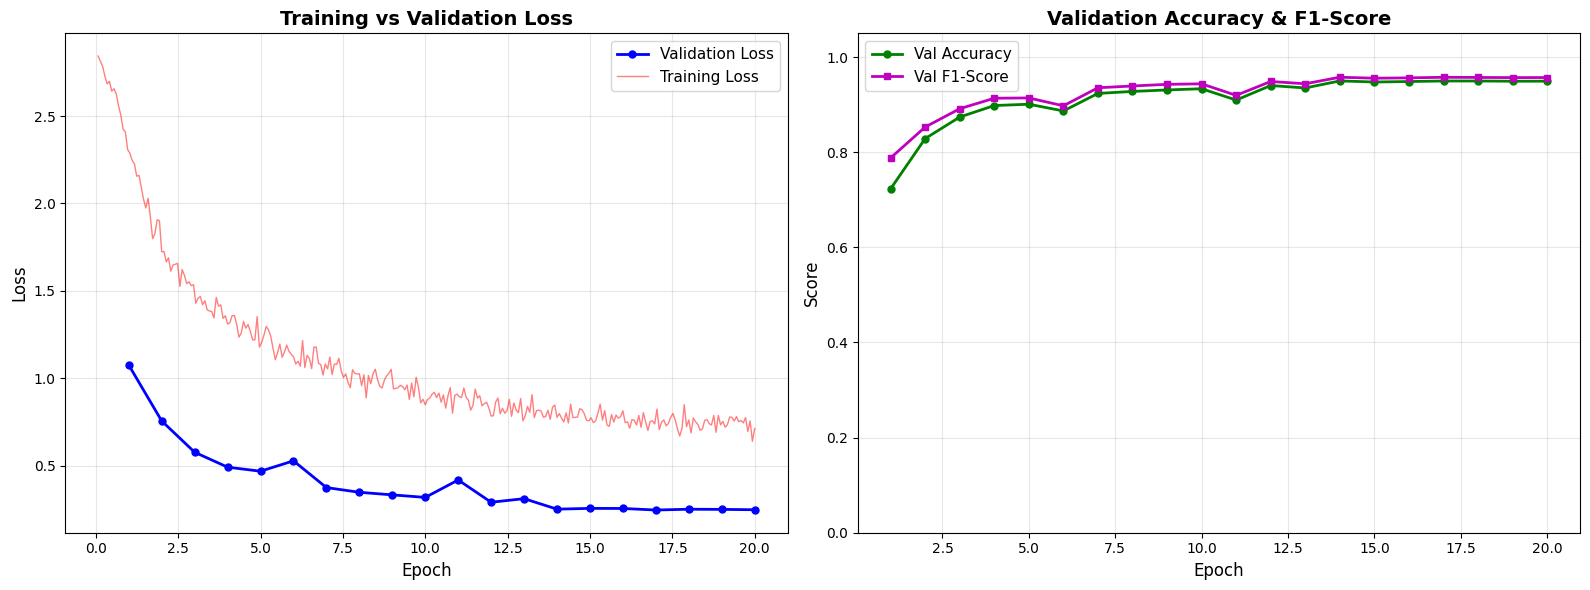

In [63]:
# --- Plot 1: Training Loss vs Validation Loss ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Loss curves
axes[0].plot(range(1, len(eval_losses)+1), eval_losses, 'b-o', label='Validation Loss', linewidth=2, markersize=5)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Add train loss as step-based (convert to epoch scale)
if train_logs:
    train_epochs_approx = [h.get('epoch', 0) for h in train_logs]
    axes[0].plot(train_epochs_approx, train_losses, 'r-', alpha=0.5, label='Training Loss', linewidth=1)
    axes[0].legend(fontsize=11)

# Accuracy & F1 curves
axes[1].plot(range(1, len(eval_accs)+1), eval_accs, 'g-o', label='Val Accuracy', linewidth=2, markersize=5)
axes[1].plot(range(1, len(eval_f1s)+1), eval_f1s, 'm-s', label='Val F1-Score', linewidth=2, markersize=5)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_title('Validation Accuracy & F1-Score', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

In [64]:
# --- Model Fit Analysis ---
print('='*60)
print('MODEL FIT ANALYSIS')
print('='*60)

if len(eval_losses) >= 3:
    best_epoch = np.argmin(eval_losses) + 1
    best_val_loss = min(eval_losses)
    final_val_loss = eval_losses[-1]
    final_val_acc = eval_accs[-1] if eval_accs else 0

    print(f'Best epoch: {best_epoch} (val_loss: {best_val_loss:.4f})')
    print(f'Final val_loss: {final_val_loss:.4f}')
    print(f'Final val_accuracy: {final_val_acc:.4f}')

    # Check for overfitting
    if len(eval_losses) > best_epoch + 2 and eval_losses[-1] > best_val_loss * 1.1:
        print('\n⚠️  OVERFITTING DETECTED')
        print('  → Validation loss increased after best epoch')
        print('  → The model loaded is from the best epoch (early stopping)')
    elif final_val_acc < 0.65:
        print('\n⚠️  POSSIBLE UNDERFITTING')
        print('  → Validation accuracy is low')
        print('  → Consider: more epochs, higher LoRA rank, or unfreezing more layers')
    else:
        print('\n✅  GOOD FIT')
        print('  → Model converged well')
        print('  → Training and validation metrics are aligned')
else:
    print('Not enough epochs to analyze fit.')

MODEL FIT ANALYSIS
Best epoch: 17 (val_loss: 0.2455)
Final val_loss: 0.2471
Final val_accuracy: 0.9494

✅  GOOD FIT
  → Model converged well
  → Training and validation metrics are aligned


# 14. Evaluation on Test Set

In [65]:
# Evaluate on truly unseen test data
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

test_results = trainer.predict(ds['test'])
print('\nTest Set Results:')
print(f'  Loss:      {test_results.metrics["test_loss"]:.4f}')
print(f'  Accuracy:  {test_results.metrics["test_accuracy"]:.4f}')
print(f'  Precision: {test_results.metrics["test_precision"]:.4f}')
print(f'  Recall:    {test_results.metrics["test_recall"]:.4f}')
print(f'  F1 Score:  {test_results.metrics["test_f1"]:.4f}')
print(f'  ROC-AUC:   {test_results.metrics["test_roc_auc"]:.4f}')


Test Set Results:
  Loss:      0.2444
  Accuracy:  0.9514
  Precision: 0.9685
  Recall:    0.9496
  F1 Score:  0.9590
  ROC-AUC:   0.9907


In [66]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, roc_curve
)

y_true = test_results.label_ids
y_pred = test_results.predictions.argmax(axis=1)
y_probs = torch.softmax(torch.tensor(test_results.predictions), dim=1).numpy()

# Classification Report
print('\n' + '='*60)
print('CLASSIFICATION REPORT')
print('='*60)
print(classification_report(y_true, y_pred, target_names=['Real', 'Fake']))

# AUC-ROC Score
auc = roc_auc_score(y_true, y_probs[:, 1])
print(f'ROC-AUC: {auc:.4f}')


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Real       0.93      0.95      0.94      3637
        Fake       0.97      0.95      0.96      5400

    accuracy                           0.95      9037
   macro avg       0.95      0.95      0.95      9037
weighted avg       0.95      0.95      0.95      9037

ROC-AUC: 0.9907


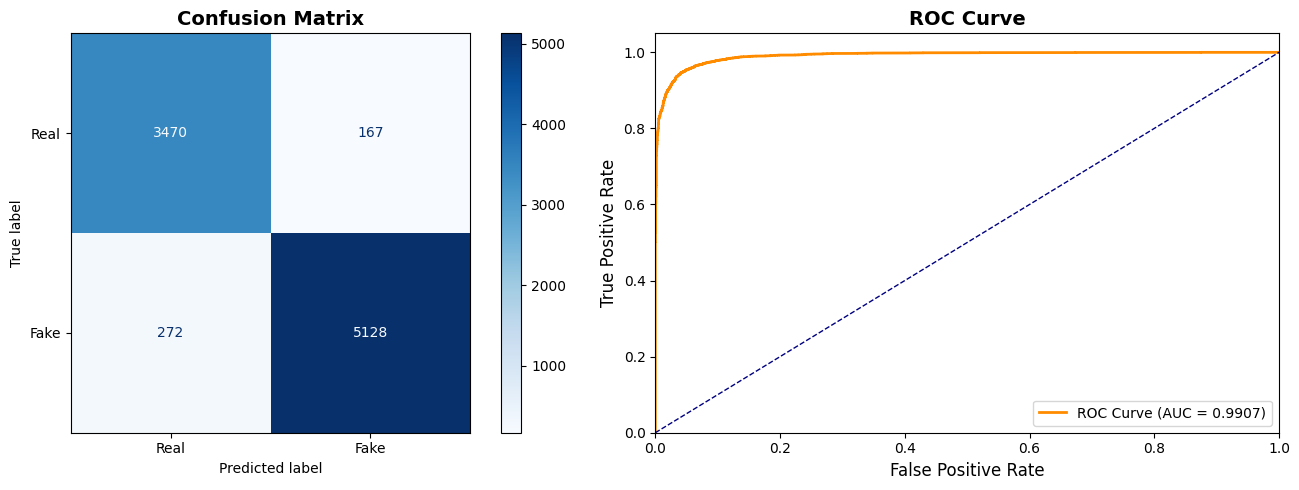

Evaluation plots saved!


In [68]:
# --- Confusion Matrix & ROC Curve ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Real', 'Fake'])
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_probs[:, 1])
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix_roc.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Evaluation plots saved!')

# 15. Save Model, Processor & Metrics

In [69]:
# Save the best LoRA model (adapter weights only — much smaller than full model)
save_path = os.path.join(OUTPUT_DIR, 'best_model_lora')
model.save_pretrained(save_path)
processor.save_pretrained(save_path)

# Save evaluation metrics
metrics_summary = {
    'model': MODEL_NAME,
    'fine_tuning': 'LoRA',
    'lora_rank': LORA_RANK,
    'lora_alpha': LORA_ALPHA,
    'total_params': total_params,
    'trainable_params': trainable_params,
    'test_loss': test_results.metrics['test_loss'],
    'test_accuracy': test_results.metrics['test_accuracy'],
    'test_precision': test_results.metrics['test_precision'],
    'test_recall': test_results.metrics['test_recall'],
    'test_f1': test_results.metrics['test_f1'],
    'test_roc_auc': test_results.metrics['test_roc_auc'],
    'epochs_trained': len(eval_losses),
    'best_epoch': int(np.argmin(eval_losses) + 1),
}

with open(os.path.join(OUTPUT_DIR, 'evaluation_metrics.json'), 'w') as f:
    json.dump(metrics_summary, f, indent=2)

print(f'LoRA model saved to: {save_path}')
print(f'Metrics saved to: {OUTPUT_DIR}/evaluation_metrics.json')
print(f'\nSaved artifacts:')
for f_name in os.listdir(OUTPUT_DIR):
    f_path = os.path.join(OUTPUT_DIR, f_name)
    if os.path.isfile(f_path):
        size_kb = os.path.getsize(f_path) / 1024
        print(f'  {f_name}: {size_kb:.1f} KB')

LoRA model saved to: /kaggle/working/TrainedModel_SwinLoRA/best_model_lora
Metrics saved to: /kaggle/working/TrainedModel_SwinLoRA/evaluation_metrics.json

Saved artifacts:
  training_history.json: 56.2 KB
  training_curves.png: 114.3 KB
  challenger_comparison.png: 1769.2 KB
  sample_visualization.png: 1696.3 KB
  evaluation_metrics.json: 0.4 KB
  confusion_matrix_roc.png: 82.0 KB
  class_distribution.png: 56.2 KB


# 16. Inference Pipeline

Predict whether a single image or video is Real or Fake using the trained LoRA model.

In [70]:
import torch.nn.functional as F
from transformers import AutoImageProcessor, SwinForImageClassification
from peft import PeftModel

def load_lora_model(model_path, base_model_name=MODEL_NAME):
    """Load trained LoRA model and processor."""
    proc = AutoImageProcessor.from_pretrained(model_path)
    base = SwinForImageClassification.from_pretrained(
        base_model_name,
        num_labels=2,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
        ignore_mismatched_sizes=True,
    )
    mdl = PeftModel.from_pretrained(base, model_path)
    mdl.to(device)
    mdl.eval()
    return proc, mdl

def predict_single_image(image, proc, mdl):
    """Predict Real/Fake for a single face image."""
    inputs = proc(images=image, return_tensors='pt').to(device)
    with torch.no_grad():
        outputs = mdl(**inputs)
    probs = F.softmax(outputs.logits, dim=1)
    pred = torch.argmax(probs, dim=1).item()
    confidence = probs[0, pred].item()
    return pred, confidence, probs.cpu().numpy()[0]

def predict_image_file(image_path, proc, mdl):
    """Predict Real/Fake for a single image file."""
    img = Image.open(image_path).convert('RGB')
    pred, confidence, probs = predict_single_image(img, proc, mdl)

    print(f'Image: {os.path.basename(image_path)}')
    print(f'  Verdict:    {ID2LABEL[pred]}')
    print(f'  Confidence: {confidence:.2%}')
    print(f'  Real prob:  {probs[0]:.4f}')
    print(f'  Fake prob:  {probs[1]:.4f}')
    return ID2LABEL[pred], confidence

print('Inference pipeline ready!')

Inference pipeline ready!


# 17. Video-Based Prediction

Predict whether a video is Real or Fake by:
1. Extracting frames at regular intervals
2. Running prediction on each frame
3. Averaging probabilities across all frames (majority voting)

In [ ]:
#Preddiction

In [71]:
def extract_frames_for_inference(video_path, frame_skip=10):
    """Extract frames from a video for prediction."""
    cap = cv2.VideoCapture(video_path)
    frames = []
    count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if count % frame_skip == 0:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(Image.fromarray(frame_rgb))
        count += 1

    cap.release()
    return frames


def predict_video(video_path, proc, mdl, frame_skip=10):
    """
    Predict whether a video is Real or Fake.
    Uses average probability across all frames for robust prediction.
    """
    frames = extract_frames_for_inference(video_path, frame_skip)

    if len(frames) == 0:
        return {'verdict': 'Error', 'reason': 'Could not read video'}

    predictions = []
    all_probs = []

    for frame in frames:
        pred, conf, probs = predict_single_image(frame, proc, mdl)
        predictions.append(pred)
        all_probs.append(probs)

    if len(predictions) == 0:
        return {'verdict': 'Unknown', 'reason': 'No predictions made'}

    # Average probability across all frames
    avg_probs = np.mean(all_probs, axis=0)
    final_pred = np.argmax(avg_probs)
    confidence = avg_probs[final_pred]

    # Vote counts
    vote_counts = Counter(predictions)

    return {
        'verdict': ID2LABEL[final_pred],
        'confidence': f'{confidence:.2%}',
        'real_prob': f'{avg_probs[0]:.4f}',
        'fake_prob': f'{avg_probs[1]:.4f}',
        'frames_analyzed': len(predictions),
        'vote_real': vote_counts.get(0, 0),
        'vote_fake': vote_counts.get(1, 0),
    }

print('Video prediction pipeline ready!')

Video prediction pipeline ready!


In [ ]:
import time

# Record the start time
start_time = time.time()
# --- Example: Test on Videos ---
# Load the trained LoRA model
model_path = os.path.join(OUTPUT_DIR, 'best_model_lora')
inf_processor, inf_model = load_lora_model(model_path)

# Test on videos (update paths as needed)
test_videos = [
    # Add your test video paths here:
    ('/kaggle/input/datasets/amiralishar/realdatas/original_016.mp4', 'Expected: Real'),
    #('/kaggle/input/datasets/amiralishar/fake-vidoe-deepfake/000_003.mp4', 'Expected: Fake'),
]

if test_videos:
    print('='*60)
    print('VIDEO PREDICTION RESULTS')
    print('='*60)

    for video_path, expected in test_videos:
        if not os.path.exists(video_path):
            print(f'\n⚠ Video not found: {video_path}')
            continue

        result = predict_video(video_path, inf_processor, inf_model)
        print(f'\n📹 {os.path.basename(video_path)}')
        print(f'   {expected}')
        for key, value in result.items():
            print(f'   {key}: {value}')
else:
    print('No test videos specified. Add video paths to the test_videos list above.')
    print('You can also use predict_image_file() for single image prediction.')

# Record the end time
end_time = time.time()

# Calculate the duration
execution_time = end_time - start_time

print(f"Execution time: {execution_time:.2f} seconds")

# 18. Summary & Final Notes

### What was accomplished:
1. ✅ Loaded pre-extracted face frames (skipped frame extraction)
2. ✅ Performed EDA (class distribution, sample visualization, resolution analysis)
3. ✅ Created challenger dataset with social media degradation augmentations
4. ✅ Built Swin Transformer + LoRA model (~2% trainable parameters)
5. ✅ Trained with Kaggle optimizations (fp16, gradient accumulation, early stopping)
6. ✅ Evaluated with full metrics (accuracy, precision, recall, F1, ROC-AUC)
7. ✅ Generated training curves and confusion matrix
8. ✅ Saved best LoRA model and all artifacts
9. ✅ Created inference pipeline for both images and videos

### Model Architecture:
- **Backbone**: Swin Transformer Tiny (pretrained on ImageNet)
- **Fine-tuning**: LoRA (rank=8, alpha=16) on attention Q/V projections
- **Classification head**: 2 classes (Real / Fake)

### Files Saved:
- `best_model_lora/` — LoRA adapter weights + processor
- `training_history.json` — Full training log
- `evaluation_metrics.json` — Test set metrics
- `training_curves.png` — Loss and accuracy plots
- `confusion_matrix_roc.png` — Confusion matrix and ROC curve
- `class_distribution.png` — Dataset class balance
- `challenger_comparison.png` — Original vs augmented samples